In [ ]:
!pip -q install plotly
import warnings, json, os
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score, roc_auc_score
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet
from scipy.spatial.distance import pdist
import plotly.graph_objects as go
from plotly.subplots import make_subplots
SEED = 11; os.makedirs('outputs', exist_ok=True); sns.set_theme(style='darkgrid', palette='deep')

In [ ]:
URL = 'https://raw.githubusercontent.com/IBM/employee-attrition-aif360/master/data/emp_attrition.csv'
try:
    df = pd.read_csv(URL, encoding='utf-8-sig')
except Exception as e:
    print('Download failed, upload the CSV manually:', e)
    from google.colab import files
    up = files.upload(); df = pd.read_csv(list(up.keys())[0], encoding='utf-8-sig')
df['Left'] = (df['Attrition'] == 'Yes').astype(int)
print(df.shape, '| attrition %.1f%%' % (100*df['Left'].mean()), '| missing:', int(df.isna().sum().sum()))

(1470, 36) | attrition 16.1% | missing: 0


## 2. Feature engineering
Attrition, PerformanceRating and PercentSalaryHike are **excluded from clustering** so they can be used afterwards to validate the segments.

In [ ]:
df['OverTimeFlag'] = (df['OverTime'] == 'Yes').astype(int)
df['TravelLevel'] = df['BusinessTravel'].map({'Non-Travel': 0, 'Travel_Rarely': 1, 'Travel_Frequently': 2})
df['IncomeToLevel'] = df['MonthlyIncome'] / df['JobLevel']
df['TenureRatio'] = df['YearsAtCompany'] / (df['TotalWorkingYears'] + 1)
df['PromotionGap'] = df['YearsSinceLastPromotion'] / (df['YearsAtCompany'] + 1)
df['SatisfactionIndex'] = df[['EnvironmentSatisfaction','JobSatisfaction','RelationshipSatisfaction','WorkLifeBalance']].mean(axis=1)
features = ['Age','DistanceFromHome','Education','JobInvolvement','JobLevel','MonthlyIncome','NumCompaniesWorked','StockOptionLevel','TotalWorkingYears',
            'TrainingTimesLastYear','YearsAtCompany','YearsInCurrentRole','YearsSinceLastPromotion','YearsWithCurrManager','OverTimeFlag','TravelLevel',
            'IncomeToLevel','TenureRatio','PromotionGap','SatisfactionIndex']
Xs = StandardScaler().fit_transform(df[features]); print(len(features), 'features')

20 features


## 3. PCA – dimensionality reduction

80% variance: 10 comps | 90% variance: 13 comps | original features: 20


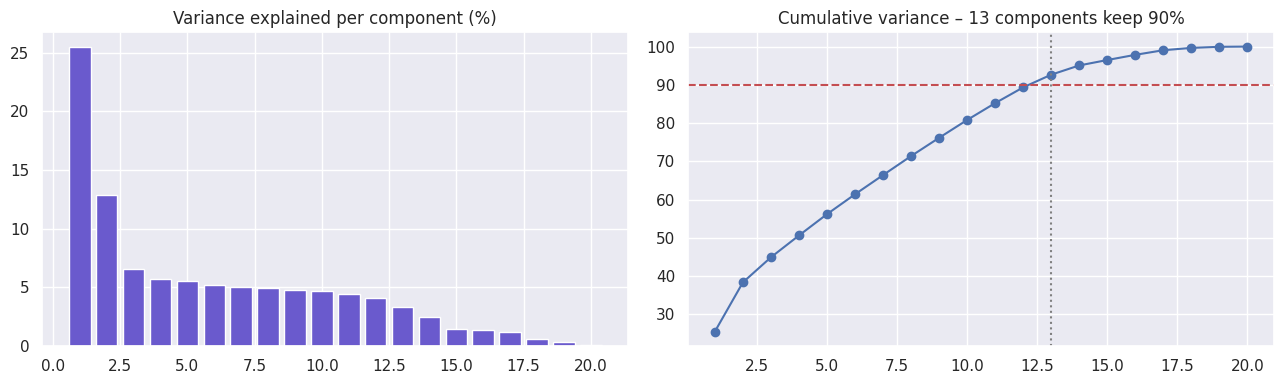

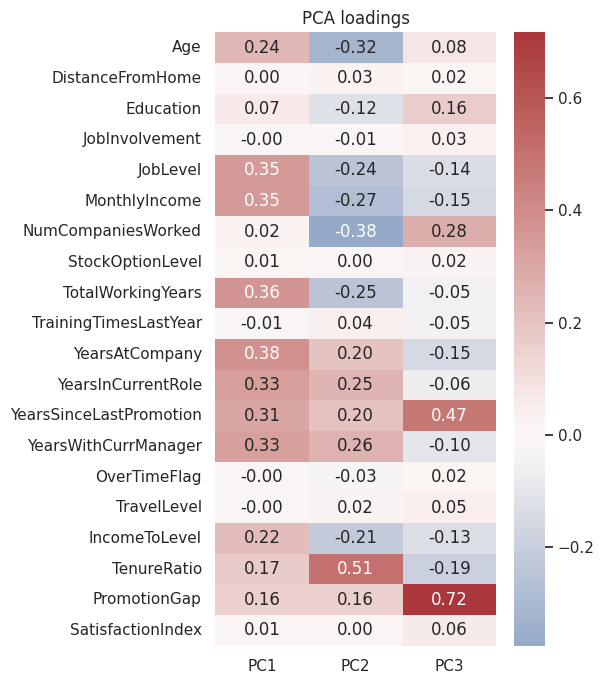

PC1: 25.5% variance | main features: ['YearsAtCompany', 'TotalWorkingYears', 'MonthlyIncome', 'JobLevel']
PC2: 12.9% variance | main features: ['TenureRatio', 'NumCompaniesWorked', 'Age', 'MonthlyIncome']
PC3: 6.6% variance | main features: ['PromotionGap', 'YearsSinceLastPromotion', 'NumCompaniesWorked', 'TenureRatio']


In [ ]:
pf = PCA(random_state=SEED).fit(Xs); cum = np.cumsum(pf.explained_variance_ratio_)
n90 = int(np.argmax(cum >= 0.90)) + 1; n80 = int(np.argmax(cum >= 0.80)) + 1
print(f'80% variance: {n80} comps | 90% variance: {n90} comps | original features: {len(features)}')
pca = PCA(n_components=n90, random_state=SEED); Z = pca.fit_transform(Xs)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(range(1, len(cum)+1), pf.explained_variance_ratio_*100, color='slateblue'); ax[0].set_title('Variance explained per component (%)')
ax[1].plot(range(1, len(cum)+1), cum*100, 'o-'); ax[1].axhline(90, color='r', ls='--'); ax[1].axvline(n90, color='gray', ls=':'); ax[1].set_title(f'Cumulative variance – {n90} components keep 90%')
plt.tight_layout(); plt.savefig('outputs/pca_variance.png', dpi=130); plt.show()
load = pd.DataFrame(pca.components_[:3].T, index=features, columns=['PC1','PC2','PC3']); load.round(3).to_csv('outputs/pca_loadings.csv')
plt.figure(figsize=(6, 7)); sns.heatmap(load, annot=True, fmt='.2f', cmap='vlag', center=0); plt.title('PCA loadings'); plt.tight_layout(); plt.savefig('outputs/pca_loadings.png', dpi=130); plt.show()
for i in range(3): print(f'PC{i+1}: %.1f%% variance | main features:' % (pca.explained_variance_ratio_[i]*100), load.iloc[:, i].abs().sort_values(ascending=False).head(4).index.tolist())

## 4. K-Means – choosing the number of segments

     inertia  silhouette  davies_bouldin  calinski
k                                                 
2  22261.409       0.191           2.008   328.262
3  20285.874       0.135           2.201   251.424
4  18786.190       0.120           2.143   219.883
5  17729.847       0.113           2.202   196.440
6  16970.727       0.112           2.234   177.166
7  16478.348       0.103           2.271   159.232
8  16172.053       0.103           2.301   142.930
9  15809.907       0.100           2.367   132.025


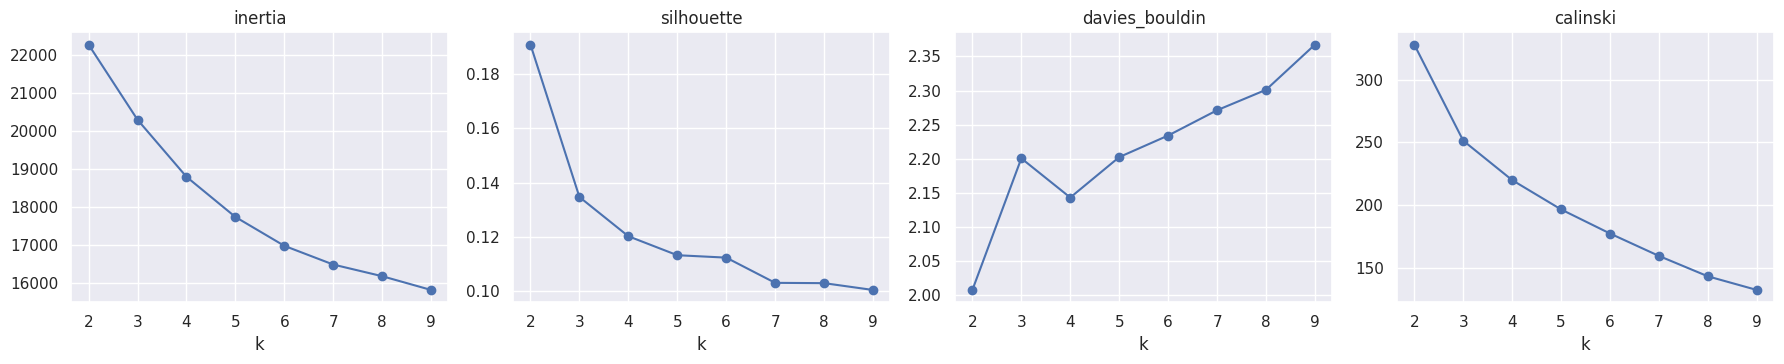

Chosen k (best silhouette among 4–6 for a granular but manageable segmentation): 4
KMeans
0    369
1    554
2    155
3    392
Name: count, dtype: int64


In [ ]:
rows = []
for k in range(2, 10):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Z)
    rows.append(dict(k=k, inertia=km.inertia_, silhouette=silhouette_score(Z, km.labels_), davies_bouldin=davies_bouldin_score(Z, km.labels_), calinski=calinski_harabasz_score(Z, km.labels_)))
sel = pd.DataFrame(rows).set_index('k'); sel.round(3).to_csv('outputs/kmeans_selection.csv'); print(sel.round(3))
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
for a, c in zip(ax, sel.columns): a.plot(sel.index, sel[c], 'o-'); a.set_title(c); a.set_xlabel('k')
plt.tight_layout(); plt.savefig('outputs/kmeans_selection.png', dpi=130); plt.show()
K = int(sel.loc[4:6, 'silhouette'].idxmax()); print('Chosen k (best silhouette among 4–6 for a granular but manageable segmentation):', K)
km = KMeans(n_clusters=K, n_init=50, random_state=SEED).fit(Z); df['KMeans'] = km.labels_; print(df['KMeans'].value_counts().sort_index())

## 5. Hierarchical clustering – linkage comparison

          cophenetic_corr  silhouette  davies_bouldin  smallest_cluster  \
linkage                                                                   
ward                0.588       0.113           2.180                92   
average             0.655       0.180           1.355                 1   
complete            0.563       0.114           2.184               120   

          ARI_vs_KMeans  
linkage                  
ward              0.448  
average           0.176  
complete          0.417  


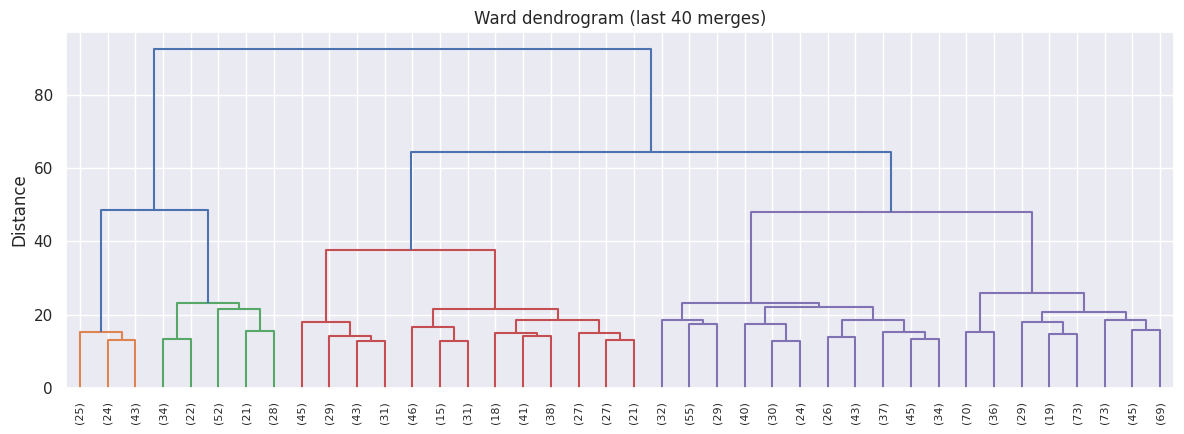

In [ ]:
hc_rows, labels_by = [], {}
for link in ['ward', 'average', 'complete']:
    L = linkage(Z, method=link); coph = cophenet(L, pdist(Z))[0]
    lab = AgglomerativeClustering(n_clusters=K, linkage=link).fit_predict(Z); labels_by[link] = lab
    hc_rows.append(dict(linkage=link, cophenetic_corr=coph, silhouette=silhouette_score(Z, lab), davies_bouldin=davies_bouldin_score(Z, lab), smallest_cluster=int(np.bincount(lab).min()), ARI_vs_KMeans=adjusted_rand_score(df['KMeans'], lab)))
hc_tab = pd.DataFrame(hc_rows).set_index('linkage'); hc_tab.round(3).to_csv('outputs/hierarchical_comparison.csv'); print(hc_tab.round(3))
df['Hier'] = labels_by['ward']
Lw = linkage(Z, 'ward'); plt.figure(figsize=(12, 4.5)); dendrogram(Lw, truncate_mode='lastp', p=40, leaf_rotation=90, color_threshold=Lw[-(K-1), 2])
plt.title('Ward dendrogram (last 40 merges)'); plt.ylabel('Distance'); plt.tight_layout(); plt.savefig('outputs/dendrogram.png', dpi=130); plt.show()

In [ ]:
km_s = silhouette_score(Z, df['KMeans']); km_d = davies_bouldin_score(Z, df['KMeans'])
cmp_ = pd.DataFrame({'K-Means': [km_s, km_d, calinski_harabasz_score(Z, df['KMeans'])], 'Hierarchical (Ward)': [hc_tab.loc['ward','silhouette'], hc_tab.loc['ward','davies_bouldin'], calinski_harabasz_score(Z, df['Hier'])]}, index=['Silhouette','Davies-Bouldin','Calinski-Harabasz']).round(3)
cmp_.to_csv('outputs/method_comparison.csv'); display(cmp_); print('Agreement K-Means vs Ward (ARI):', round(adjusted_rand_score(df['KMeans'], df['Hier']), 3))
display(pd.crosstab(df['KMeans'], df['Hier'], rownames=['KMeans'], colnames=['Ward']))

,K-Means,Hierarchical (Ward)
Silhouette,0.121,0.113
Davies-Bouldin,2.141,2.180
Calinski-Harabasz,219.911,187.062


Agreement K-Means vs Ward (ARI): 0.448


Ward,0,1,2,3
KMeans,,,,
0,283,2,14,70
1,497,0,57,0
2,1,129,4,21
3,28,26,337,1


## 6. Segment profiles and automatic descriptive names

,Employees,Attrition_pct,Age,Income,JobLevel,Tenure,OverTime_pct,SatisfactionIdx,PromoGap,Stock,Performance
Segment,,,,,,,,,,,
Entry-Level Early Career,554,23.47,30.63,3322.58,1.26,3.59,28.16,2.72,0.71,0.70,3.15
Experienced Newcomers,369,13.55,43.22,8015.49,2.42,3.52,32.79,2.74,0.67,0.85,3.14
Senior Veterans,155,8.39,46.51,15514.41,4.06,19.23,28.39,2.73,6.93,0.78,3.15
Stable Mid-Career,392,11.22,36.10,6010.59,2.07,10.29,24.23,2.74,3.82,0.88,3.17


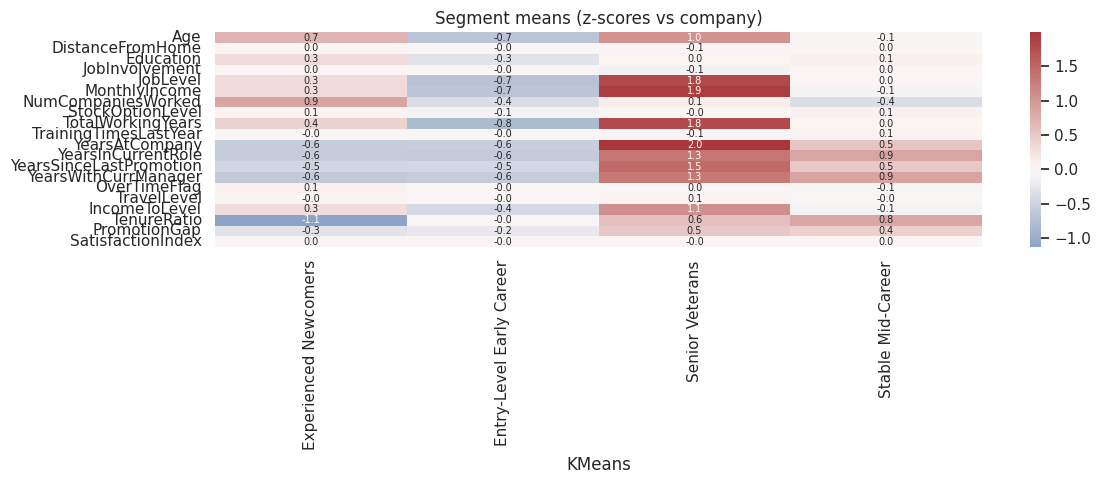

In [ ]:
zs = (df.groupby('KMeans')[features].mean() - df[features].mean()) / df[features].std()
def describe(i):
    top = zs.loc[i].abs().sort_values(ascending=False).index[:2]
    return f'S{i}: ' + ', '.join(('High ' if zs.loc[i, f] > 0 else 'Low ') + f for f in top)
NAMES = {i: describe(i) for i in range(K)}
if K == 4:   # business-friendly names assigned by rules, so they stay correct if cluster ids change between runs
    g = df.groupby('KMeans').agg(inc=('MonthlyIncome','mean'), ten=('YearsAtCompany','mean')); order = g['inc'].sort_values().index.tolist()
    low, high, mid = order[0], order[-1], order[1:3]; mid = sorted(mid, key=lambda i: g.loc[i, 'ten'])
    NAMES = {low: 'Entry-Level Early Career', mid[0]: 'Experienced Newcomers', mid[1]: 'Stable Mid-Career', high: 'Senior Veterans'}
df['Segment'] = df['KMeans'].map(NAMES)
prof = df.groupby('Segment').agg(Employees=('Left','size'), Attrition_pct=('Left', lambda s: 100*s.mean()), Age=('Age','mean'), Income=('MonthlyIncome','mean'), JobLevel=('JobLevel','mean'),
        Tenure=('YearsAtCompany','mean'), OverTime_pct=('OverTimeFlag', lambda s: 100*s.mean()), SatisfactionIdx=('SatisfactionIndex','mean'), PromoGap=('YearsSinceLastPromotion','mean'),
        Stock=('StockOptionLevel','mean'), Performance=('PerformanceRating','mean')).round(2)
prof.to_csv('outputs/segment_profiles.csv'); zs.round(2).to_csv('outputs/segment_zscores.csv'); display(prof)
plt.figure(figsize=(12, 5)); sns.heatmap(zs.rename(index=NAMES).T, cmap='vlag', center=0, annot=True, fmt='.1f', annot_kws={'size': 7}); plt.title('Segment means (z-scores vs company)')
plt.tight_layout(); plt.savefig('outputs/segment_heatmap.png', dpi=130); plt.show()

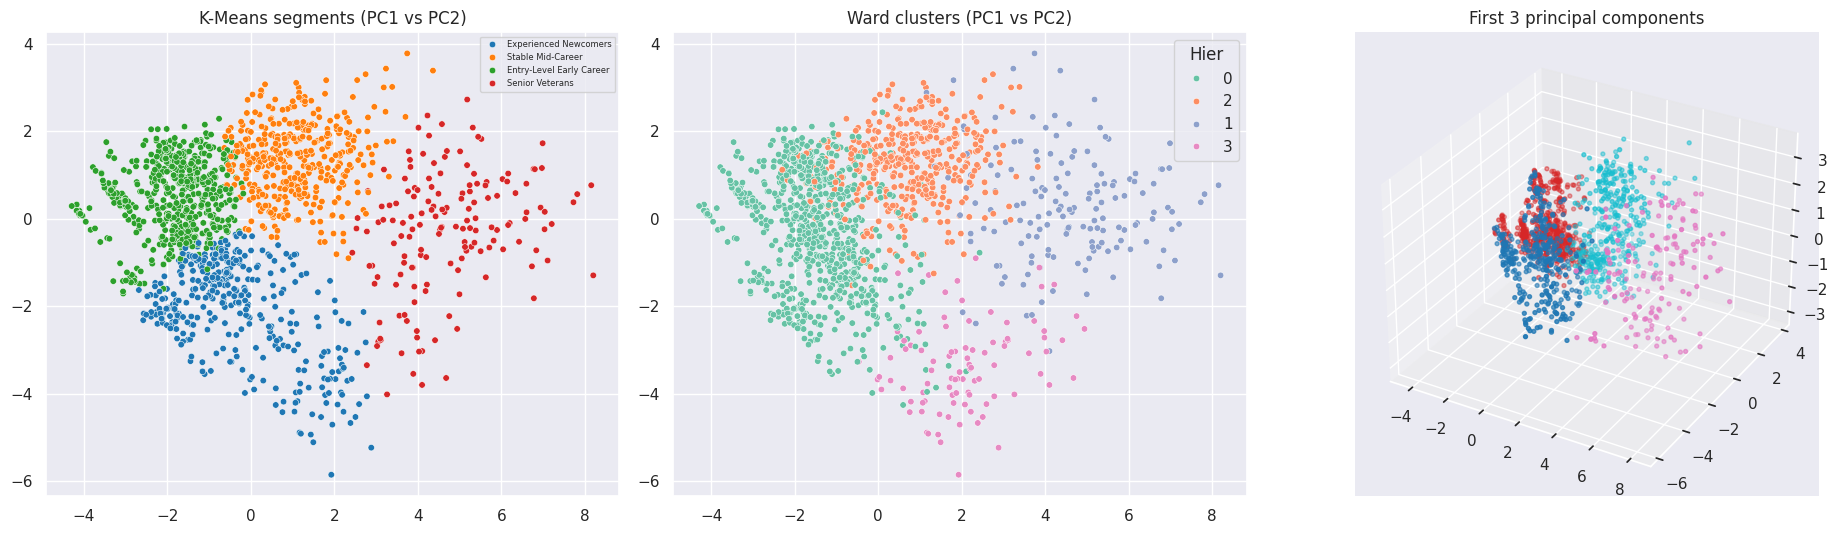

In [ ]:
fig = plt.figure(figsize=(19, 5.5)); a1 = fig.add_subplot(1, 3, 1); a2 = fig.add_subplot(1, 3, 2); a3 = fig.add_subplot(1, 3, 3, projection='3d')
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=df['Segment'], palette='tab10', s=22, ax=a1); a1.set_title('K-Means segments (PC1 vs PC2)'); a1.legend(fontsize=6)
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=df['Hier'].astype(str), palette='Set2', s=22, ax=a2); a2.set_title('Ward clusters (PC1 vs PC2)')
a3.scatter(Z[:, 0], Z[:, 1], Z[:, 2], c=df['KMeans'], cmap='tab10', s=8); a3.set_title('First 3 principal components')
plt.tight_layout(); plt.savefig('outputs/pca_clusters.png', dpi=130); plt.show()

## 7. Department-level workforce segments

Segment,Entry-Level Early Career,Experienced Newcomers,Senior Veterans,Stable Mid-Career
Department,,,,
Human Resources,44.4,23.8,14.3,17.5
Research & Development,39.4,25.2,10.4,25.0
Sales,33.0,25.1,10.3,31.6


,Employees,Attrition_pct,Income,OverTime_pct,Satisfaction
Department,,,,,
Human Resources,63,19.05,6654.51,26.98,2.77
Research & Development,961,13.84,6281.25,28.20,2.73
Sales,446,20.63,6959.17,28.70,2.74


,Sub,Department,Employees,Attrition_pct,Income,Tenure,OverTime_pct
0,0,Human Resources,6,0.0,17651.3,6.5,33.3
1,1,Human Resources,50,22.0,3981.0,5.0,26.0
2,2,Human Resources,7,14.3,16324.9,24.1,28.6
0,0,Research & Development,592,17.2,3717.8,4.0,28.4
1,1,Research & Development,115,5.2,13801.4,5.1,27.8
2,2,Research & Development,254,9.8,8851.2,14.2,28.0
0,0,Sales,149,12.1,6598.2,9.9,25.5
1,1,Sales,63,14.3,14582.8,16.3,27.0
2,2,Sales,234,27.8,5136.5,3.2,31.2


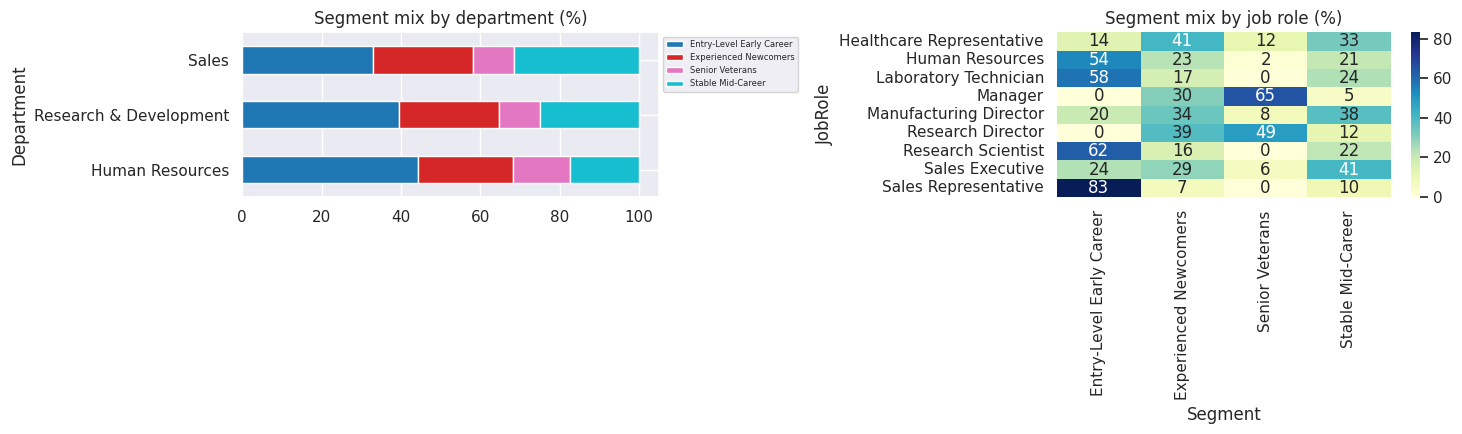

In [ ]:
dep_mix = pd.crosstab(df['Department'], df['Segment'], normalize='index').mul(100).round(1); dep_mix.to_csv('outputs/department_segment_mix.csv'); display(dep_mix)
dep_stats = df.groupby('Department').agg(Employees=('Left','size'), Attrition_pct=('Left', lambda s: 100*s.mean()), Income=('MonthlyIncome','mean'), OverTime_pct=('OverTimeFlag', lambda s: 100*s.mean()), Satisfaction=('SatisfactionIndex','mean')).round(2)
dep_stats.to_csv('outputs/department_stats.csv'); display(dep_stats)
# separate 3-group K-Means inside each department (department-specific segments)
sub = []
for d, g in df.groupby('Department'):
    zz = PCA(n_components=0.9, random_state=SEED).fit_transform(StandardScaler().fit_transform(g[features]))
    lab = KMeans(3, n_init=20, random_state=SEED).fit_predict(zz); gg = g.assign(Sub=lab)
    t = gg.groupby('Sub').agg(Employees=('Left','size'), Attrition_pct=('Left', lambda s: 100*s.mean()), Income=('MonthlyIncome','mean'), Tenure=('YearsAtCompany','mean'), OverTime_pct=('OverTimeFlag', lambda s: 100*s.mean())).round(1)
    t.insert(0, 'Department', d); sub.append(t.reset_index())
sub = pd.concat(sub); sub.to_csv('outputs/department_subsegments.csv', index=False); display(sub)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5)); dep_mix.plot(kind='barh', stacked=True, ax=ax[0], colormap='tab10'); ax[0].legend(fontsize=6, bbox_to_anchor=(1, 1)); ax[0].set_title('Segment mix by department (%)')
sns.heatmap(pd.crosstab(df['JobRole'], df['Segment'], normalize='index').mul(100), annot=True, fmt='.0f', cmap='YlGnBu', ax=ax[1]); ax[1].set_title('Segment mix by job role (%)')
plt.tight_layout(); plt.savefig('outputs/department_segments.png', dpi=130); plt.show()

## 8. Performance groups
A performance & engagement index is built from PerformanceRating, JobInvolvement, PercentSalaryHike and TrainingTimesLastYear (z-scores averaged), then split into three groups.

In [ ]:
comp = df[['PerformanceRating','JobInvolvement','PercentSalaryHike','TrainingTimesLastYear']]; idx = ((comp - comp.mean()) / comp.std()).mean(axis=1)
df['PerfIndex'] = idx; df['PerfGroup'] = pd.qcut(idx.rank(method='first'), 3, labels=['Low performers', 'Core performers', 'High performers'])
perf = df.groupby('PerfGroup', observed=True).agg(Employees=('Left','size'), Attrition_pct=('Left', lambda s: 100*s.mean()), Income=('MonthlyIncome','mean'), Rating=('PerformanceRating','mean'), Involvement=('JobInvolvement','mean')).round(2)
perf_seg = pd.crosstab(df['Segment'], df['PerfGroup'], normalize='index').mul(100).round(1); perf.to_csv('outputs/performance_groups.csv'); perf_seg.to_csv('outputs/performance_by_segment.csv'); display(perf); display(perf_seg)
hp = df[df['PerfGroup'] == 'High performers']; print('High performers who left: %d (%.1f%% of high performers)' % (hp['Left'].sum(), 100*hp['Left'].mean()))

,Employees,Attrition_pct,Income,Rating,Involvement
PerfGroup,,,,,
Low performers,490,21.84,6676.13,3.00,2.29
Core performers,490,13.27,6569.95,3.00,2.91
High performers,490,13.27,6262.71,3.46,2.99


PerfGroup,Low performers,Core performers,High performers
Segment,,,
Entry-Level Early Career,33.6,33.6,32.9
Experienced Newcomers,32.5,33.1,34.4
Senior Veterans,35.5,36.1,28.4
Stable Mid-Career,32.9,32.1,34.9


High performers who left: 65 (13.3% of high performers)


## 9. Retention-risk groups (model-based)
A logistic regression is used only as a **risk scorer**: out-of-fold probabilities (5-fold) are produced for every employee, so no one is scored by a model that saw their own outcome. Tiers: **High** = top 20% of scores, **Medium** = next 30%, **Low** = rest.

Out-of-fold ROC-AUC of the risk score: 0.839


,Employees,Leavers,Attrition_pct
RiskTier,,,
High,294,154,52.4
Medium,441,53,12.0
Low,735,30,4.1


High tier captures 65.0% of all leavers


RiskTier,High,Medium,Low
Segment,,,
Entry-Level Early Career,29.4,36.3,34.3
Experienced Newcomers,18.7,29.3,52.0
Senior Veterans,11.6,17.4,71.0
Stable Mid-Career,11.2,26.8,62.0


,Employees,Attrition_pct
Segment,,
Entry-Level Early Career,554,23.5
Experienced Newcomers,369,13.6
Senior Veterans,155,8.4
Stable Mid-Career,392,11.2


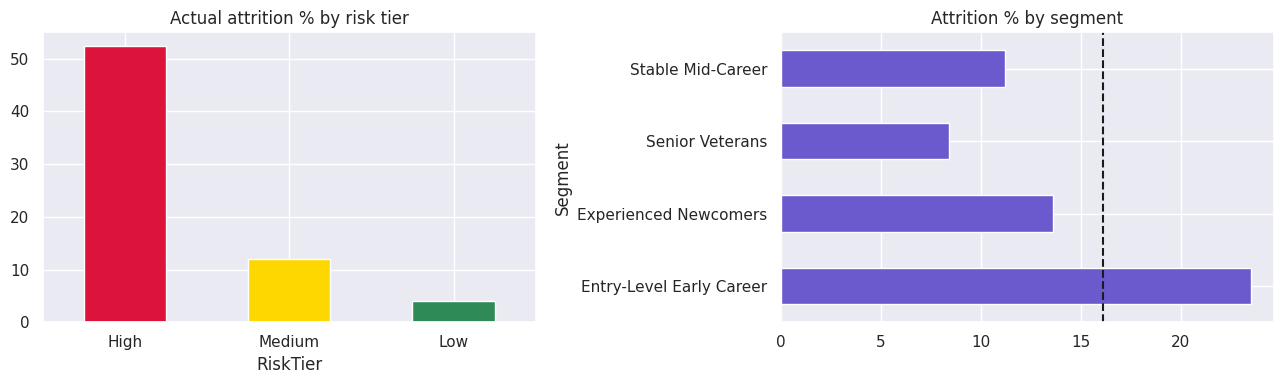

In [ ]:
Xm = pd.get_dummies(df[features + ['Department','JobRole','MaritalStatus','Gender']], drop_first=True).astype(float)
from sklearn.pipeline import make_pipeline
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.1, class_weight='balanced'))
df['RiskScore'] = cross_val_predict(pipe, Xm, df['Left'], cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method='predict_proba')[:, 1]
auc = roc_auc_score(df['Left'], df['RiskScore']); print('Out-of-fold ROC-AUC of the risk score: %.3f' % auc)
q80, q50 = df['RiskScore'].quantile([0.80, 0.50]); df['RiskTier'] = np.where(df['RiskScore'] >= q80, 'High', np.where(df['RiskScore'] >= q50, 'Medium', 'Low'))
tiers = df.groupby('RiskTier').agg(Employees=('Left','size'), Leavers=('Left','sum'), Attrition_pct=('Left', lambda s: 100*s.mean())).round(1).reindex(['High','Medium','Low']); tiers.to_csv('outputs/retention_risk_groups.csv'); display(tiers)
print('High tier captures %.1f%% of all leavers' % (100*tiers.loc['High','Leavers']/df['Left'].sum()))
seg_risk = pd.crosstab(df['Segment'], df['RiskTier'], normalize='index').mul(100).round(1).reindex(columns=['High','Medium','Low']); seg_risk.to_csv('outputs/risk_by_segment.csv'); display(seg_risk)
seg_attr = df.groupby('Segment')['Left'].agg(['size', lambda s: 100*s.mean()]).round(1); seg_attr.columns = ['Employees', 'Attrition_pct']; seg_attr.to_csv('outputs/attrition_by_segment.csv'); display(seg_attr)
fig, ax = plt.subplots(1, 2, figsize=(13, 4)); tiers['Attrition_pct'].plot(kind='bar', ax=ax[0], color=['crimson','gold','seagreen']); ax[0].set_title('Actual attrition % by risk tier'); ax[0].tick_params(axis='x', rotation=0)
seg_attr['Attrition_pct'].plot(kind='barh', ax=ax[1], color='slateblue'); ax[1].axvline(100*df['Left'].mean(), color='k', ls='--'); ax[1].set_title('Attrition % by segment')
plt.tight_layout(); plt.savefig('outputs/risk_groups.png', dpi=130); plt.show()

## 10. Workforce Analytics Dashboard (interactive, with department filter)

In [ ]:
segs = sorted(df['Segment'].unique()); P = ['#1f77b4','#ff7f0e','#2ca02c','#d62728','#9467bd','#8c564b','#e377c2']; cmap = {s: P[i % 7] for i, s in enumerate(segs)}
deps = sorted(df['Department'].unique()); overall = 100*df['Left'].mean()
fig = make_subplots(rows=3, cols=4, specs=[[{'type':'indicator'}]*4, [{'colspan':2,'type':'xy'}, None, {'type':'xy'}, {'type':'xy'}], [{'type':'xy'}, {'type':'xy'}, {'type':'xy'}, {'type':'xy'}]],
    row_heights=[0.12, 0.45, 0.43], vertical_spacing=0.11, horizontal_spacing=0.07,
    subplot_titles=('', '', '', '', 'Employee map (PCA) – use the department filter', 'Attrition % by risk tier', 'Attrition % by segment', 'Segment size', 'Segment mix by department', 'Performance group vs attrition %', 'Avg satisfaction index', 'Years since promotion'))
for i, (t, v, f) in enumerate([('Employees', len(df), None), ('Attrition rate %', overall, '.1f'), ('Segments', K, None), ('High-risk employees', int((df['RiskTier']=='High').sum()), None)]):
    fig.add_trace(go.Indicator(mode='number', value=v, title=dict(text=t, font=dict(size=14)), number=dict(valueformat=f) if f else {}), row=1, col=i+1)
combos = []
for d in deps:
    for s in segs:
        m = ((df['Department'] == d) & (df['Segment'] == s)).values
        fig.add_trace(go.Scatter(x=Z[m, 0], y=Z[m, 1], mode='markers', name=s, legendgroup=s, showlegend=(d == deps[0]), marker=dict(color=cmap[s], size=5, opacity=0.75),
                                 text=df.loc[m, 'JobRole'], hovertemplate='%{text}<extra>'+s+'</extra>'), row=2, col=1); combos.append(d)
n_scatter = len(combos)
fig.add_trace(go.Bar(x=tiers.index, y=tiers['Attrition_pct'], marker_color=['crimson','gold','seagreen'], text=tiers['Attrition_pct'], textposition='outside', showlegend=False), row=2, col=3)
fig.add_trace(go.Bar(x=[s for s in seg_attr.index], y=seg_attr['Attrition_pct'], marker_color=[cmap[s] for s in seg_attr.index], text=seg_attr['Attrition_pct'], textposition='outside', showlegend=False, customdata=seg_attr.index, hovertemplate='%{customdata}<br>%{y}%<extra></extra>'), row=2, col=4)
fig.add_trace(go.Bar(x=[s for s in seg_attr.index], y=seg_attr['Employees'], marker_color=[cmap[s] for s in seg_attr.index], showlegend=False, customdata=seg_attr.index, hovertemplate='%{customdata}<br>%{y} employees<extra></extra>'), row=3, col=1)
for s in segs: fig.add_trace(go.Bar(x=dep_mix.index, y=dep_mix[s], name=s, marker_color=cmap[s], showlegend=False), row=3, col=2)
fig.add_trace(go.Bar(x=perf.index.astype(str), y=perf['Attrition_pct'], marker_color='#555', showlegend=False, text=perf['Attrition_pct'], textposition='outside'), row=3, col=3)
sat = df.groupby('Segment')['SatisfactionIndex'].mean().reindex(segs).round(2); fig.add_trace(go.Bar(x=[s for s in segs], y=sat.values, marker_color=[cmap[s] for s in segs], showlegend=False), row=3, col=4)
buttons = [dict(label='All departments', method='update', args=[{'visible': [True]*len(fig.data)}])]
for d in deps:
    vis = [True]*len(fig.data)
    for j, c in enumerate(combos): vis[4 + j] = (c == d)
    buttons.append(dict(label=d, method='update', args=[{'visible': vis}]))
fig.update_layout(barmode='stack', updatemenus=[dict(buttons=buttons, direction='down', x=0.0, y=0.66, xanchor='left', yanchor='top', showactive=True)], height=1100, template='plotly_dark',
                  title=dict(text='<b>Workforce Analytics Dashboard</b> – segmentation, performance and retention risk', x=0.01), legend=dict(orientation='h', y=0.70, x=0.0, font=dict(size=9)), margin=dict(t=90))
fig.write_html('Workforce_Analytics_Dashboard.html', include_plotlyjs=True); fig.show()

## 11. Save results

In [ ]:
df[['EmployeeNumber','Department','JobRole','Attrition','KMeans','Hier','Segment','PerfGroup','RiskScore','RiskTier']].to_csv('outputs/employee_segments.csv', index=False)
summary = dict(k=K, n80=n80, n90=n90, n_features=len(features), var_pc=[float(v) for v in pca.explained_variance_ratio_[:3]], cum_n90=float(cum[n90-1]), sil_km=float(km_s), dbi_km=float(km_d),
               sil_hc=float(hc_tab.loc['ward','silhouette']), dbi_hc=float(hc_tab.loc['ward','davies_bouldin']), ari=float(adjusted_rand_score(df['KMeans'], df['Hier'])), risk_auc=float(auc),
               overall_attrition=float(overall), names={int(k): v for k, v in NAMES.items()})
json.dump(summary, open('outputs/summary.json', 'w'), indent=2); print(summary)

{'k': 4, 'n80': 10, 'n90': 13, 'n_features': 20, 'var_pc': [0.25473806711221114, 0.12866769880268145, 0.06556496564799037], 'cum_n90': 0.9265074381625323, 'sil_km': 0.12099329199811494, 'dbi_km': 2.1409925929662323, 'sil_hc': 0.11286552654472153, 'dbi_hc': 2.1804950816388144, 'ari': 0.4483656760014255, 'risk_auc': 0.8390772737072285, 'overall_attrition': 16.122448979591837, 'names': {1: 'Entry-Level Early Career', 0: 'Experienced Newcomers', 3: 'Stable Mid-Career', 2: 'Senior Veterans'}}
